# Lab 3: Basic Quantum Registers
**Student:** ยามาอัลลุดดีน เจ๊ะหามะ (Ang) — AISE Cohort 3

Contents: Lab Tasks 1–5 → Exercises 1–5 → Concept Questions 1–5

## Part A — Lab Tasks
### Task 1 — Setup

In [1]:
!pip install -q qiskit qiskit-aer pylatexenc

In [2]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
from qiskit_aer import Aer, AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 1024
backend = Aer.get_backend('aer_simulator')

def run(circ, shots=SHOTS, sim=backend, seed=42):
    """Run a circuit on the simulator and return its counts."""
    return sim.run(transpile(circ, sim), shots=shots, seed_simulator=seed).result().get_counts()

### Task 2 — Creating Registers Explicitly

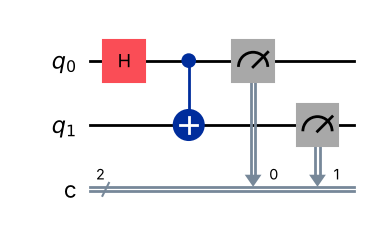

In [3]:
qreg = QuantumRegister(2, 'q')   # 2 qubits
creg = ClassicalRegister(2, 'c') # 2 classical bits
qc = QuantumCircuit(qreg, creg)

qc.h(qreg[0])
qc.cx(qreg[0], qreg[1])
qc.measure(qreg, creg)

qc.draw('mpl')

### Task 3 — Implicit Register Creation

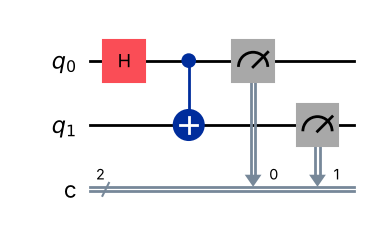

In [4]:
qc2 = QuantumCircuit(2, 2)
qc2.h(0)
qc2.cx(0, 1)
qc2.measure([0, 1], [0, 1])
qc2.draw('mpl')

In [5]:
# Qiskit created the registers automatically:
print('Quantum registers  :', qc2.qregs)
print('Classical registers:', qc2.cregs)

Quantum registers  : [QuantumRegister(2, 'q')]
Classical registers: [ClassicalRegister(2, 'c')]


### Task 4 — Running the Circuit

{'11': 503, '00': 521}


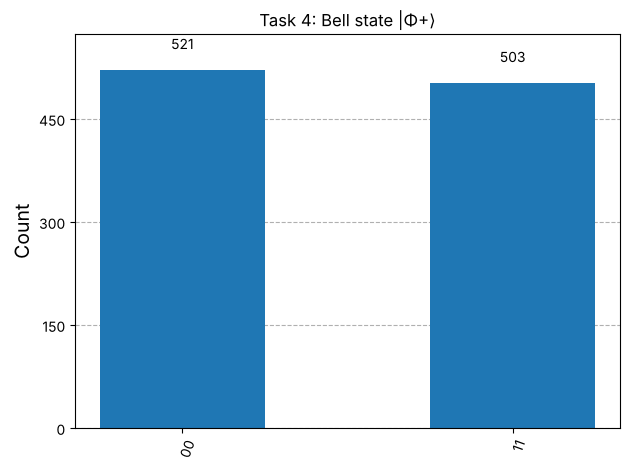

In [6]:
counts = run(qc)
print(counts)
plot_histogram(counts, title='Task 4: Bell state |Φ+⟩')

**Observation:** Only `00` and `11` appear, each ≈ 50%. The two qubits are entangled — they are never measured as different values.

### Task 5 — Multi-Register Example

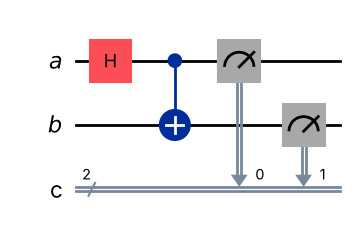

In [7]:
qreg1 = QuantumRegister(1, 'a')
qreg2 = QuantumRegister(1, 'b')
creg = ClassicalRegister(2, 'c')

qc3 = QuantumCircuit(qreg1, qreg2, creg)
qc3.h(qreg1[0])
qc3.cx(qreg1[0], qreg2[0])
qc3.measure([qreg1[0], qreg2[0]], [creg[0], creg[1]])
qc3.draw('mpl')

{'11': 503, '00': 521}


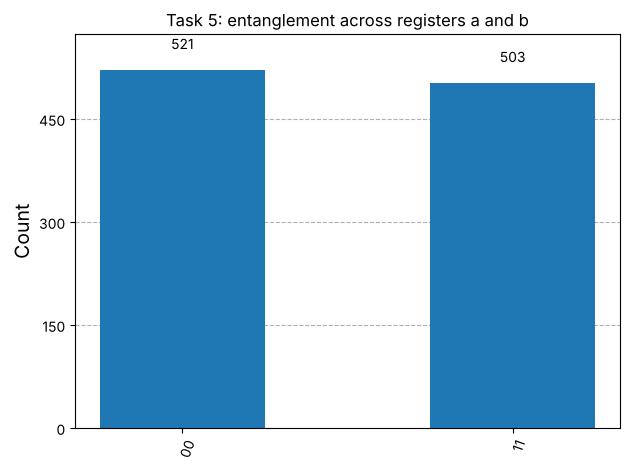

In [8]:
counts3 = run(qc3)
print(counts3)
plot_histogram(counts3, title='Task 5: entanglement across registers a and b')

**Observation:** Same result as Task 4. Splitting qubits into different registers is only *naming/grouping* — it does not change the physics.

## Part B — Exercises

### Exercise 1 — Register Allocation: 3 qubits, H on each

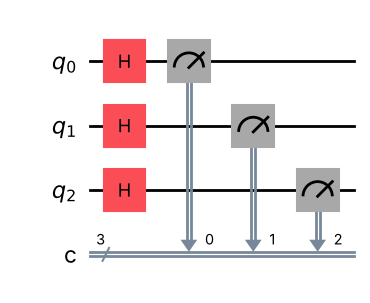

{'110': 115, '011': 123, '111': 135, '001': 142, '000': 109, '010': 141, '100': 125, '101': 134}


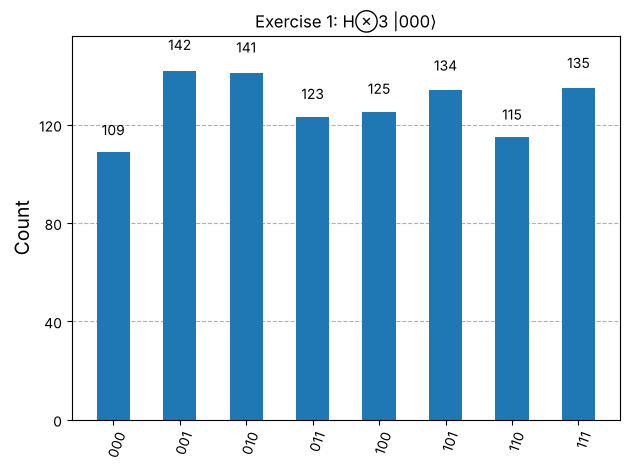

In [9]:
qr = QuantumRegister(3, 'q')
cr = ClassicalRegister(3, 'c')
ex1 = QuantumCircuit(qr, cr)
ex1.h(qr)             # H on every qubit of the register
ex1.measure(qr, cr)
display(ex1.draw('mpl'))

counts_ex1 = run(ex1)
print(counts_ex1)
plot_histogram(counts_ex1, title='Exercise 1: H⊗3 |000⟩')

**Result:** All 2³ = 8 outcomes (`000` … `111`) appear with roughly equal frequency (≈ 1024/8 = 128 each).

**Why:** H|0⟩ = (|0⟩+|1⟩)/√2. The three qubits are independent, so the state is
(H|0⟩)⊗3 = (1/√8) Σₓ |x⟩ — a *uniform superposition*, each |αₓ|² = 1/8.
The small differences between bars are statistical (shot) noise from using a finite number of shots.

### Exercise 2 — Two 2-qubit registers, entangle one qubit from each

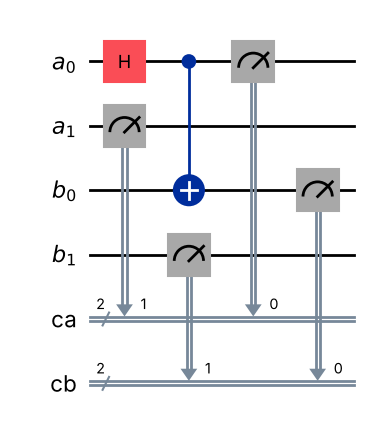

{'01 01': 518, '00 00': 506}


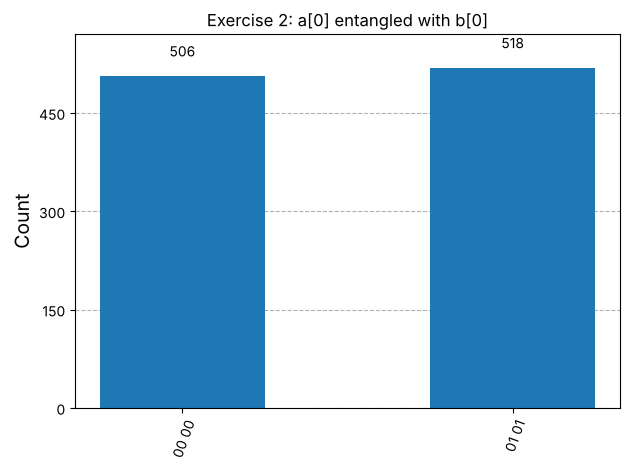

In [10]:
ra = QuantumRegister(2, 'a')
rb = QuantumRegister(2, 'b')
ca = ClassicalRegister(2, 'ca')
cb = ClassicalRegister(2, 'cb')
ex2 = QuantumCircuit(ra, rb, ca, cb)

ex2.h(ra[0])            # superposition on a[0]
ex2.cx(ra[0], rb[0])    # entangle a[0] with b[0]  (across registers)
ex2.measure(ra, ca)
ex2.measure(rb, cb)
display(ex2.draw('mpl'))

counts_ex2 = run(ex2)
print(counts_ex2)
plot_histogram(counts_ex2, title='Exercise 2: a[0] entangled with b[0]')

**Result:** Only `01 01` and `00 00` appear (≈ 50% each).

Reading the key: Qiskit prints classical registers separated by a space, the *last-added* register first → `cb ca`. Inside each register the bit at index 0 is on the right.
- `01 01` → a[0]=1 and b[0]=1
- `00 00` → a[0]=0 and b[0]=0

So a[0] and b[0] are always equal (entangled), while a[1] and b[1] stay in |0⟩ because nothing acted on them. Entanglement works across register boundaries.

### Exercise 3 — Mapping: measure `qreg[0]` into `creg[1]`

A Bell state gives `00`/`11`, which look identical if bits are swapped — so the effect would be invisible.
To *see* the mapping we use an asymmetric state: X on `q[0]` only → state |01⟩ (q0 = 1, q1 = 0).

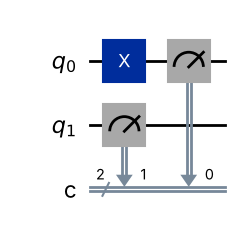

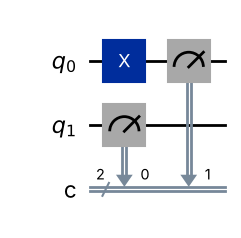

Normal  (q0→c0, q1→c1): {'01': 1024}
Crossed (q0→c1, q1→c0): {'10': 1024}


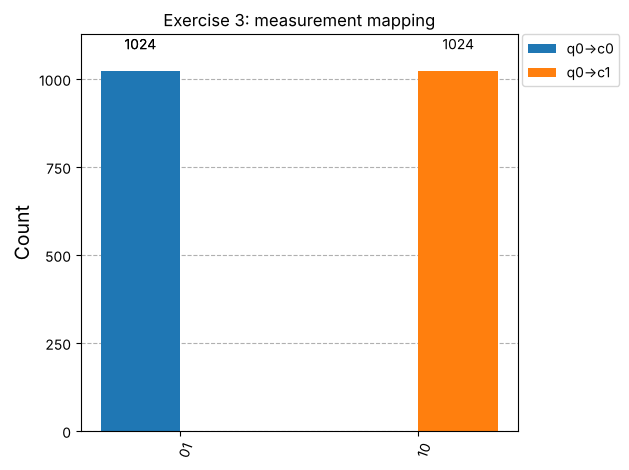

In [11]:
def mapping_demo(swap):
    q = QuantumRegister(2, 'q')
    c = ClassicalRegister(2, 'c')
    circ = QuantumCircuit(q, c)
    circ.x(q[0])                       # q0 = 1, q1 = 0
    if swap:
        circ.measure(q[0], c[1])       # crossed wiring
        circ.measure(q[1], c[0])
    else:
        circ.measure(q[0], c[0])       # normal wiring
        circ.measure(q[1], c[1])
    return circ

normal  = mapping_demo(swap=False)
crossed = mapping_demo(swap=True)
display(normal.draw('mpl'))
display(crossed.draw('mpl'))

c_normal, c_crossed = run(normal), run(crossed)
print('Normal  (q0→c0, q1→c1):', c_normal)
print('Crossed (q0→c1, q1→c0):', c_crossed)
plot_histogram([c_normal, c_crossed], legend=['q0→c0', 'q0→c1'], title='Exercise 3: measurement mapping')

**Result:**
- Normal mapping → `01` (string is printed as `c1 c0`, so c0 = 1 on the right).
- Crossed mapping → `10` (now the `1` from q0 lands in c1, the left position).

**Conclusion:** The quantum state did not change at all — only *where the answer is written* changed. The classical register is just a labelled storage slot; wiring the wrong qubit to the wrong bit silently reorders the result. Qiskit uses **little-endian** order (bit 0 = rightmost character), so the mapping must be tracked carefully.

Bell-state check (for comparison):

In [12]:
bell_cross = QuantumCircuit(2, 2)
bell_cross.h(0); bell_cross.cx(0, 1)
bell_cross.measure(0, 1); bell_cross.measure(1, 0)
print('Bell state with crossed mapping:', run(bell_cross))   # still only 00 / 11

Bell state with crossed mapping: {'11': 503, '00': 521}


### Exercise 4 — 3-qubit GHZ: explicit registers vs `QuantumCircuit(3,3)`

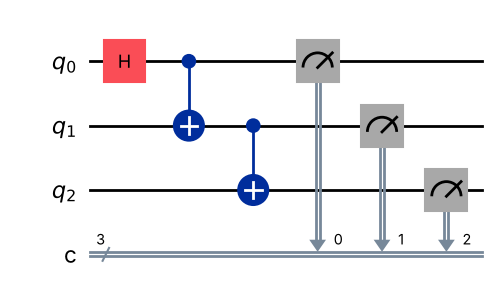

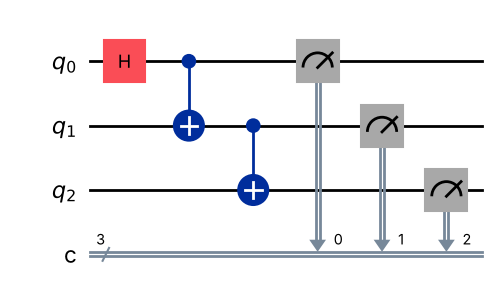

(a) explicit : {'000': 490, '111': 534}
(b) implicit : {'000': 490, '111': 534}


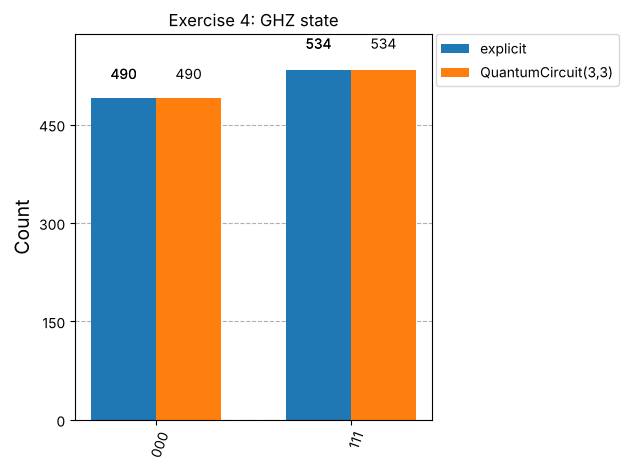

In [13]:
# (a) Explicit registers
qr = QuantumRegister(3, 'q')
cr = ClassicalRegister(3, 'c')
ghz_a = QuantumCircuit(qr, cr)
ghz_a.h(qr[0])
ghz_a.cx(qr[0], qr[1])
ghz_a.cx(qr[1], qr[2])
ghz_a.measure(qr, cr)

# (b) Direct / implicit style
ghz_b = QuantumCircuit(3, 3)
ghz_b.h(0)
ghz_b.cx(0, 1)
ghz_b.cx(1, 2)
ghz_b.measure([0, 1, 2], [0, 1, 2])

display(ghz_a.draw('mpl'))
display(ghz_b.draw('mpl'))

ca_, cb_ = run(ghz_a), run(ghz_b)
print('(a) explicit :', ca_)
print('(b) implicit :', cb_)
plot_histogram([ca_, cb_], legend=['explicit', 'QuantumCircuit(3,3)'], title='Exercise 4: GHZ state')

In [14]:
from qiskit.quantum_info import Operator
a_noM, b_noM = ghz_a.remove_final_measurements(inplace=False), ghz_b.remove_final_measurements(inplace=False)
print('Same unitary?        ', Operator(a_noM).equiv(Operator(b_noM)))
print('Register names (a):  ', [r.name for r in ghz_a.qregs], [r.name for r in ghz_a.cregs])
print('Register names (b):  ', [r.name for r in ghz_b.qregs], [r.name for r in ghz_b.cregs])

Same unitary?         True
Register names (a):   ['q'] ['c']
Register names (b):   ['q'] ['c']


**Comparison**

| | (a) Explicit registers | (b) `QuantumCircuit(3,3)` |
|---|---|---|
| Physics / result | GHZ: only `000` and `111`, ≈ 50% each | identical |
| Unitary | — | equal to (a) (checked with `Operator.equiv`) |
| How qubits are addressed | `qr[0]`, `qr[1]` — by name | `0, 1, 2` — by integer index |
| Registers | named by us (`q`, `c`) | auto-generated by Qiskit |
| Best for | multi-part algorithms (data/ancilla/output) | small, quick circuits |

The two styles build the *same* circuit; the difference is only readability and organisation.

### Exercise 5 (Optional) — Depolarizing noise on a 2-qubit register

NoiseModel:
  Basis gates: ['cx', 'h', 'id', 'rz', 'sx', 'x']
  Instructions with noise: ['cx', 'h', 'x']
  All-qubits errors: ['h', 'x', 'cx']


Ideal : {'11': 503, '00': 521}
Noisy : {'01': 28, '10': 25, '00': 498, '11': 473}


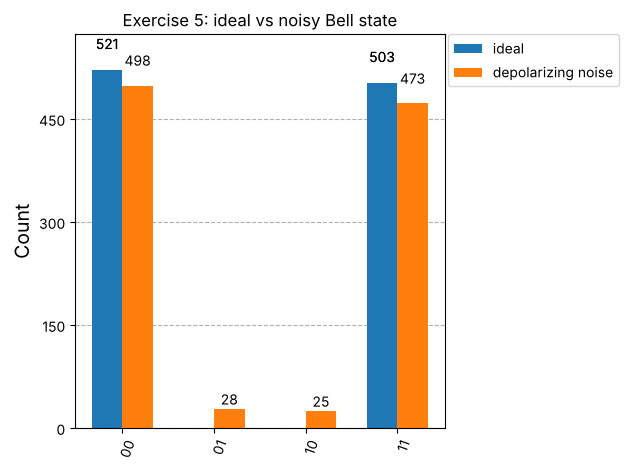

In [15]:
noise_model = NoiseModel()
p1, p2 = 0.05, 0.10   # error probability for 1-qubit and 2-qubit gates (exaggerated to make it visible)
noise_model.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ['h', 'x'])
noise_model.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ['cx'])
print(noise_model)

noisy_sim = AerSimulator(noise_model=noise_model)

ideal = run(qc)                    # Bell circuit from Task 2
noisy = run(qc, sim=noisy_sim)
print('Ideal :', ideal)
print('Noisy :', noisy)
plot_histogram([ideal, noisy], legend=['ideal', 'depolarizing noise'], title='Exercise 5: ideal vs noisy Bell state')

In [16]:
def fidelity_like(counts):
    good = counts.get('00', 0) + counts.get('11', 0)
    return good / sum(counts.values())

print(f"Ideal  P(00 or 11) = {fidelity_like(ideal):.3f}")
print(f"Noisy  P(00 or 11) = {fidelity_like(noisy):.3f}")

Ideal  P(00 or 11) = 1.000
Noisy  P(00 or 11) = 0.948


**Observation:** In the ideal simulation only `00` and `11` occur. With depolarizing noise, the "forbidden" outcomes `01` and `10` appear, and P(00 or 11) drops below 1.

Depolarizing noise means: with probability *p* the gate output is replaced by a random (maximally mixed) state. Since `cx` has a larger error rate than `h`, the entangling step is the main source of error — which is also true on real hardware, where two-qubit gates are the noisiest operations.

## Part C — Concept Questions

**1. Why do we need classical registers in addition to quantum registers?**
A quantum state cannot be read directly; measuring it collapses it to a single classical outcome. That outcome has to be stored somewhere — the classical register. Classical bits are also what we read after the run (counts/histograms), and they allow classical feedback (mid-circuit measurement and conditional gates, e.g. in teleportation or error correction).

**2. What is the difference between creating registers explicitly vs implicitly in Qiskit?**
*Explicit:* we create `QuantumRegister`/`ClassicalRegister` objects with our own names and sizes, then build the circuit from them; qubits are addressed as `qreg[i]`. Useful when an algorithm has several logical parts.
*Implicit:* `QuantumCircuit(n, m)` creates default registers (`q`, `c`) automatically; qubits are addressed by integer index. Shorter, good for small circuits.
Both produce the same circuit and the same results (Exercise 4).

**3. Can a circuit exist without registers? Why or why not?**
A circuit can be *created* with no qubits (`QuantumCircuit()`), but it cannot do anything — gates need qubits to act on, so a useful circuit always has qubits. In Qiskit those qubits are normally held in registers (created by us or automatically). Qiskit also allows loose `Qubit()`/`Clbit()` objects that do not belong to a named register, so strictly speaking a named register is not required — but bits are. A circuit without classical bits can still exist and be simulated as a statevector; it simply cannot store measurement results.

**4. How does the number of classical bits affect the ability to record measurement results?**
Each measured qubit needs one classical bit to store its result. With *m* classical bits we can record at most *m* qubit outcomes (2ᵐ possible patterns). If there are fewer classical bits than measured qubits, some results cannot be stored, or a later measurement overwrites an earlier one in the same bit — information is lost. Extra classical bits are allowed but stay 0.

**5. In an algorithm like Grover's, why is it important to manage registers carefully?**
Grover's algorithm uses qubits with different roles: a search register (holds the superposition of candidate answers), often an ancilla/oracle qubit (e.g. prepared in |−⟩ for phase kickback), and classical bits for the answer. Separate, well-named registers make sure that:
- H gates and the diffuser act only on the search register, not on the ancilla;
- the oracle connects the correct qubits;
- only the search register is measured, and into the correct classical bits in the correct order (as shown in Exercise 3, wrong mapping silently gives a wrong answer).
As circuits grow, clear register management prevents bugs and makes the algorithm readable.